# Predicting Checkout Spend to Target Free Shipping
**Haoran Fan · Regression, cross-validation, Ridge and Lasso**

**Business question.** Free shipping costs OmniShop \$8 per order. The Chief Revenue Officer wants to offer it only to shoppers likely to spend \$150 or more. Today Finance assumes every shopper spends the average, which cannot tell a \$60 shopper from a \$180 one. I built a regression model that predicts each shopper's checkout spend, then used it to decide who gets the offer.

**Data.** 1,500 checkout sessions from signed-in shoppers, with 15 candidate features. The target is `total_checkout_spend`.

**Result.** My recommended Lasso model cut the typical prediction error from \$42 to about \$22 per shopper, kept only 7 of 103 inputs, and wasted the least money on free-shipping offers (\$104 on the test set).

### How I approached it
| Step | What I did | Why |
|---|---|---|
| 1 | Predicted the average for everyone | Set the bar any model must beat |
| 2 | Fit OLS on the 4 features the team trusts most | Start simple and read coefficients in dollars |
| 3 | Plotted the residuals | Find where the model goes wrong |
| 4 | Added all 15 features, one group at a time | Test whether more data helps or overfits |
| 5 | Compared models with 5-fold cross-validation | Choose a model without touching the test set |
| 6 | Tuned Ridge and Lasso | Keep the useful features, penalize the noise |
| 7 | Compared all four models on the test set | Check the choice on unseen shoppers |
| 8 | Applied each model to the \$150 rule | Turn accuracy into dollars for the business |

In [ ]:
# ============================================================
# SETUP AND DATA
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score


def rmse(actual, predicted):
    """Root mean squared error, in dollars."""
    return np.sqrt(mean_squared_error(actual, predicted))

# --- OmniShop checkout sessions (synthetic, fixed random seed) ---
rng = np.random.default_rng(42)
N = 1500
historical_aov = np.round(np.clip(rng.lognormal(np.log(95), 0.5, N), 10, None), 2)
pages_viewed = rng.poisson(6, N) + 1
session_duration_min = np.round(np.clip(pages_viewed * 2.0 + rng.normal(0, 1.5, N), 1, None), 1)
discount_applied = rng.choice([0, 1], N, p=[0.7, 0.3])
items = rng.integers(1, 6, N)
price = rng.uniform(8, 40, N)
recommended_item_value = np.round(items * price, 2)

df = pd.DataFrame({
    "historical_aov": historical_aov,
    "pages_viewed": pages_viewed,
    "session_duration_min": session_duration_min,
    "discount_applied": discount_applied,
    "recommended_item_value": recommended_item_value,
    "device_type": rng.choice(["desktop", "mobile", "tablet"], N, p=[0.45, 0.45, 0.10]),
    "region_cluster": rng.choice([f"cluster_{i:02d}" for i in range(1, 61)], N),
    "session_hour": rng.integers(0, 24, N).astype(str),
    "session_weekday": rng.choice(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], N),
    "traffic_source": rng.choice(["search", "email", "social", "direct"], N),
    "account_age_days": rng.integers(30, 2000, N),
    "email_subscriber": rng.choice([0, 1], N),
    "saved_items": rng.poisson(3, N),
    "wishlist_items": rng.poisson(4, N),
    "promo_emails_opened": rng.poisson(2, N),
})
spend = (12 + 0.60 * historical_aov + 1.80 * pages_viewed - 12 * discount_applied
         + 0.25 * recommended_item_value + rng.normal(0, 10 + 0.10 * historical_aov))
big = np.zeros(N, bool)
big[rng.choice(N, 8, replace=False)] = True
spend = spend + big * rng.uniform(1000, 2400, N)
df["total_checkout_spend"] = np.round(np.clip(spend, 5, None), 2)

print(f"{len(df):,} checkout sessions · average spend ${df.total_checkout_spend.mean():,.2f}")
df.head()

1,500 checkout sessions · average spend $111.82


,historical_aov,pages_viewed,session_duration_min,discount_applied,recommended_item_value,device_type,region_cluster,session_hour,session_weekday,traffic_source,account_age_days,email_subscriber,saved_items,wishlist_items,promo_emails_opened,total_checkout_spend
0,110.63,6,11.9,0,165.74,mobile,cluster_10,2,Fri,direct,1904,1,1,4,3,105.48
1,56.48,5,8.1,0,23.91,tablet,cluster_51,1,Sun,social,1006,0,3,2,5,49.75
2,138.26,9,18.1,0,25.24,desktop,cluster_22,15,Mon,direct,1793,0,6,3,2,131.58
3,152.04,8,13.2,0,46.01,mobile,cluster_56,13,Wed,direct,1788,0,1,1,3,147.95
4,35.81,8,15.1,0,65.96,mobile,cluster_07,16,Tue,email,1106,1,4,2,3,67.25


## Step 1 · Baseline
Before building any model, I measured how wrong the simplest guess is: Finance's approach of predicting the average spend for every shopper. I held back 30% of sessions as a test set to stand in for new shoppers and left it untouched until the final checks.

In [ ]:
# STEP 1 · BASELINE: predict the average for everyone
target = "total_checkout_spend"
X = df.drop(columns=target)
y = df[target]

# 70% to learn from, 30% held back as "new shoppers"
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

average_guess = y_train.mean()
print(f"Finance's guess for every shopper: ${average_guess:,.2f}")
print(f"Typical miss on new shoppers (test RMSE): ${rmse(y_test, np.full(len(y_test), average_guess)):,.2f}")

Finance's guess for every shopper: $112.89
Typical miss on new shoppers (test RMSE): $114.16


**What I found:** the average guess is \$112.89, and it misses new shoppers by about \$114. That error is larger than the average itself, a first sign that a few very large orders are distorting the data. Every model from here has to beat this number.

## Step 2 · A simple linear model
I started with OLS on the 4 features the team trusts most: past order value, pages viewed, discount and recommended item value.

In [ ]:
# STEP 2 · A SIMPLE LINEAR MODEL with the 4 features the team trusts most
simple_features = ["historical_aov", "pages_viewed", "discount_applied", "recommended_item_value"]

model_with_big = LinearRegression().fit(X_train[simple_features], y_train)

print(f"Test R²:   {r2_score(y_test, model_with_big.predict(X_test[simple_features])):.3f}")
print(f"Test RMSE: ${rmse(y_test, model_with_big.predict(X_test[simple_features])):,.2f}")

Test R²:   0.100
Test RMSE: $108.23


**What I found:** the model beats the average guess, but R² is only 0.10, so it explains very little of the variation in spend. Something in the data is hurting it, so I looked at the errors next.

## Step 3 · Residual analysis
A residual is *actual − predicted*. A good model leaves residuals scattered evenly around zero.

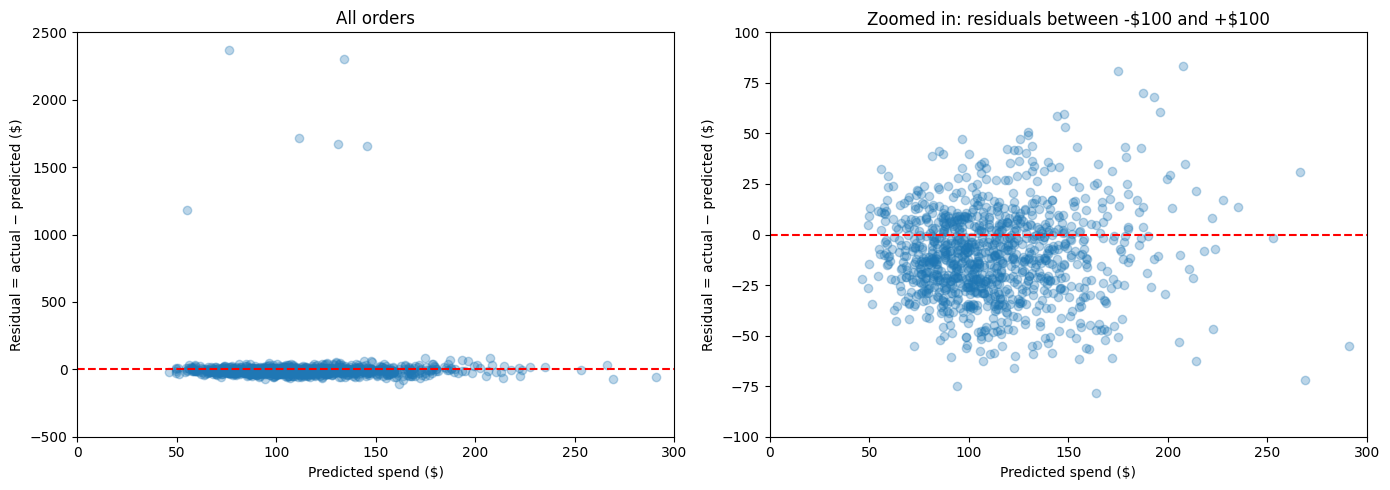

Orders of $1,000 or more: 8 in the full data, 6 in the training set


In [ ]:
# STEP 3 · RESIDUAL PLOT: where is the model wrong?
pred_train = model_with_big.predict(X_train[simple_features])
residuals = y_train - pred_train

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, ylim, title in [(axes[0], (-500, 2500), "All orders"),
                        (axes[1], (-100, 100), r"Zoomed in: residuals between -\$100 and +\$100")]:
    ax.scatter(pred_train, residuals, alpha=0.3)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_xlim(0, 300); ax.set_ylim(*ylim)
    ax.set_xlabel("Predicted spend ($)"); ax.set_ylabel("Residual = actual − predicted ($)")
    ax.set_title(title)
plt.tight_layout(); plt.show()

print("Orders of $1,000 or more:", (y >= 1000).sum(), "in the full data,", (y_train >= 1000).sum(), "in the training set")

**What I found:**
- **Left:** a few points sit far above everything else. These are 8 VIP orders of \$1,000 or more.
- **Right:** most points sit *below* zero, so the model over-predicts ordinary shoppers.
- **Right:** the spread widens as predictions grow, so big spenders are harder to predict.

**Why 8 orders matter so much.** OLS minimizes *squared* errors, so a few very large errors dominate the total. To shrink them, OLS pulls the whole line upward toward the big orders, and every ordinary shopper gets over-predicted.

**Business rule.** OmniShop's VIP team already serves big-order shoppers personally, and they are not part of the free-shipping offer. From here on, I model standard shoppers only (orders under \$1,000).

In [ ]:
# STEP 3b · Model standard shoppers only
standard_train, standard_test = y_train < 1000, y_test < 1000
X_std_train, y_std_train = X_train[standard_train], y_train[standard_train]
X_std_test, y_std_test = X_test[standard_test], y_test[standard_test]

simple_model = LinearRegression().fit(X_std_train[simple_features], y_std_train)

print(f"Standard shoppers in the test set: {len(y_std_test)}")
print(f"Average over-prediction for them, model trained WITH big orders:    "
      f"${(model_with_big.predict(X_std_test[simple_features]) - y_std_test).mean():+.2f}")
print(f"Average over-prediction for them, model trained WITHOUT big orders: "
      f"${(simple_model.predict(X_std_test[simple_features]) - y_std_test).mean():+.2f}")
print(f"\nNew simple model — test R²: {r2_score(y_std_test, simple_model.predict(X_std_test[simple_features])):.3f}, "
      f"test RMSE: ${rmse(y_std_test, simple_model.predict(X_std_test[simple_features])):,.2f}")
print(f"Average guess for standard shoppers — test RMSE: "
      f"${rmse(y_std_test, np.full(len(y_std_test), y_std_train.mean())):,.2f}")

print(f"\nIntercept: ${simple_model.intercept_:,.2f}")
display(pd.DataFrame({"$ change in predicted spend per +1 unit": simple_model.coef_}, index=simple_features).round(2))

Standard shoppers in the test set: 448
Average over-prediction for them, model trained WITH big orders:    $+9.28
Average over-prediction for them, model trained WITHOUT big orders: $-0.87

New simple model — test R²: 0.732, test RMSE: $21.69
Average guess for standard shoppers — test RMSE: $41.92

Intercept: $8.94


,$ change in predicted spend per +1 unit
historical_aov,0.61
pages_viewed,2.07
discount_applied,-10.80
recommended_item_value,0.24


**What I found:** removing 8 orders out of 1,500 removed a \$9 over-prediction for every standard shopper. R² jumped from 0.10 to 0.73, and the typical error fell to \$21.69, about half of the \$41.92 baseline for standard shoppers.

**Caveat for launch.** At prediction time we do not yet know who will place a \$1,000 order, so VIP shoppers need to be identified another way first, for example from a VIP customer list.

### Reading the model in dollars
To check that the coefficients make business sense, I scored one example shopper by hand and with code: past order value \$120, 8 pages viewed, no discount, and \$100 of recommended items.

*predicted spend* = 8.94 + 0.61 × 120 + 2.07 × 8 − 10.80 × 0 + 0.24 × 100 ≈ **\$122.7**

In [ ]:
shopper = pd.DataFrame([{
    "historical_aov": 120,
    "pages_viewed": 8,
    "discount_applied": 0,
    "recommended_item_value": 100,
}])
print(f"Model prediction: ${simple_model.predict(shopper)[0]:.2f}")


Model prediction: $122.60


In plain terms for the CRO:
- **Pages viewed:** holding everything else constant, each extra page a shopper views adds about \$2.07 to predicted spend.
- **Discount:** shoppers who were shown a discount are predicted to spend about \$10.80 less than similar shoppers who were not.

## Step 4 · Adding all 15 candidate features
The data team engineered 15 fields, including 60 regional clusters and session time (hour and weekday). I tested whether more information actually helps.

In [ ]:
# STEP 4 · ADD ALL 15 CANDIDATE FEATURES
num_features = ["historical_aov", "pages_viewed", "session_duration_min", "discount_applied", "recommended_item_value",
                "account_age_days", "email_subscriber", "saved_items", "wishlist_items", "promo_emails_opened"]
cat_features = ["device_type", "region_cluster", "session_hour", "session_weekday", "traffic_source"]

def make_preprocessor(num, cat):
    """Scale the numbers; turn each category into 0/1 columns."""
    parts = [("num", StandardScaler(), num)]
    if cat:
        parts.append(("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat))
    return ColumnTransformer(parts)

full_model = Pipeline([("prep", make_preprocessor(num_features, cat_features)),
                       ("model", LinearRegression())]).fit(X_std_train, y_std_train)

# A helper that scores any model on standard shoppers and adds a row to the `results` table
results = pd.DataFrame(columns=["Inputs used", "Train R²", "Test R²", "Test RMSE ($)"])

def score(name, model, features=None):
    Xtr = X_std_train if features is None else X_std_train[features]
    Xte = X_std_test if features is None else X_std_test[features]
    coefs = model.named_steps["model"].coef_ if hasattr(model, "named_steps") else model.coef_
    results.loc[name] = [int((coefs != 0).sum()),
                         round(r2_score(y_std_train, model.predict(Xtr)), 3),
                         round(r2_score(y_std_test, model.predict(Xte)), 3),
                         round(rmse(y_std_test, model.predict(Xte)), 2)]
    results["Inputs used"] = results["Inputs used"].astype(int)
    return results

score("Simple OLS (4 features)", simple_model, simple_features)
score("Full OLS (15 features)", full_model)

,Inputs used,Train R²,Test R²,Test RMSE ($)
Simple OLS (4 features),4,0.737,0.732,21.69
Full OLS (15 features),103,0.769,0.684,23.58


**What I found:** the 15 fields became 103 model inputs, because each category turns into its own 0/1 column. Training R² rose from 0.737 to 0.769, but test R² fell from 0.732 to 0.684. The full model was capturing noise, patterns that only exist in this sample and do not repeat on new shoppers. That is **overfitting**.

To see where it starts, I added feature groups one at a time and tracked training error against cross-validation error.

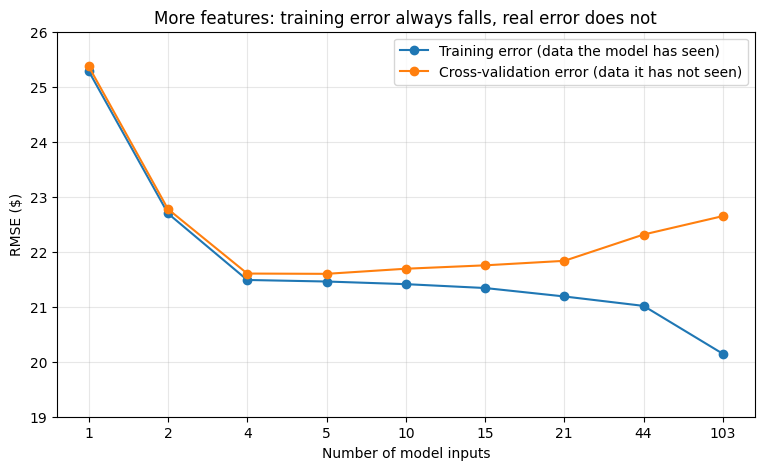

,Model inputs,Train RMSE,CV RMSE
0,1,25.28,25.37
1,2,22.70,22.77
2,4,21.49,21.60
3,5,21.46,21.60
4,10,21.41,21.69
5,15,21.34,21.75
6,21,21.19,21.83
7,44,21.02,22.31
8,103,20.14,22.65


In [ ]:
# STEP 4b · UNDERFIT → SWEET SPOT → OVERFIT: add features one group at a time
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)
ladder = [
    (["historical_aov"], []),
    (["historical_aov", "recommended_item_value"], []),
    (simple_features, []),
    (simple_features + ["session_duration_min"], []),
    (num_features, []),
    (num_features, ["device_type", "traffic_source"]),
    (num_features, ["device_type", "traffic_source", "session_weekday"]),
    (num_features, ["device_type", "traffic_source", "session_weekday", "session_hour"]),
    (num_features, cat_features),
]
rows = []
for num, cat in ladder:
    pipe = Pipeline([("prep", make_preprocessor(num, cat)), ("model", LinearRegression())]).fit(X_std_train, y_std_train)
    rows.append({"Model inputs": len(pipe.named_steps["model"].coef_),
                 "Train RMSE": rmse(y_std_train, pipe.predict(X_std_train)),
                 "CV RMSE": -cross_val_score(pipe, X_std_train, y_std_train, cv=cv5,
                                             scoring="neg_root_mean_squared_error").mean()})
curve = pd.DataFrame(rows)

plt.figure(figsize=(9, 5))
plt.plot(range(len(curve)), curve["Train RMSE"], marker="o", label="Training error (data the model has seen)")
plt.plot(range(len(curve)), curve["CV RMSE"], marker="o", label="Cross-validation error (data it has not seen)")
plt.xticks(range(len(curve)), curve["Model inputs"])
plt.xlabel("Number of model inputs"); plt.ylabel("RMSE ($)")
plt.ylim(19, 26); plt.legend(); plt.grid(alpha=0.3)
plt.title("More features: training error always falls, real error does not")
plt.show()
display(curve.round(2))

**What I found:**
- **1–2 inputs:** both errors are high. The model is too simple (**underfitting**).
- **4 inputs:** cross-validation error is lowest, at \$21.60. This is the sweet spot.
- **44–103 inputs:** training error keeps falling, but cross-validation error rises (**overfitting**).

## Step 5 · Cross-validation
To compare models without touching the test set, I used 5-fold cross-validation: train on 4 parts of the training data, score on the 5th, repeat 5 times and average.

In [ ]:
# STEP 5 · CROSS-VALIDATION: an honest score without touching the test set
cv_simple = -cross_val_score(LinearRegression(), X_std_train[simple_features], y_std_train, cv=cv5,
                             scoring="neg_root_mean_squared_error")
cv_full = -cross_val_score(full_model, X_std_train, y_std_train, cv=cv5, scoring="neg_root_mean_squared_error")
print("Simple OLS — RMSE in each of the 5 folds:", np.round(cv_simple, 2), f"→ average ${cv_simple.mean():.2f}")
print("Full OLS   — RMSE in each of the 5 folds:", np.round(cv_full, 2), f"→ average ${cv_full.mean():.2f}")

Simple OLS — RMSE in each of the 5 folds: [20.8  20.29 20.13 23.53 23.26] → average $21.60
Full OLS   — RMSE in each of the 5 folds: [21.97 21.7  20.69 24.38 24.5 ] → average $22.65


**What I found:** scores vary from fold to fold, which is why averaging matters. Cross-validation picked the simple model over the full one *before* the test set was used, and its estimates later matched the test results within about a dollar.

## Step 6 · Ridge and Lasso
Regularization keeps all the features but charges a penalty for large coefficients. I tuned the penalty strength (alpha) over 61 values with cross-validation, with scaling and encoding inside a pipeline so no test information leaks into training.
- **Ridge (L2)** shrinks every coefficient toward zero and shares weight between features that move together.
- **Lasso (L1)** can set coefficients to exactly zero, which drops features that do not help.

In [ ]:
# STEP 6 · RIDGE AND LASSO: keep all 15 features, but penalize big coefficients
alphas = np.logspace(-3, 3, 61)   # penalty strengths to try, from 0.001 to 1,000

def tune(model):
    """Try every alpha with 5-fold cross-validation and keep the best one."""
    pipe = Pipeline([("prep", make_preprocessor(num_features, cat_features)), ("model", model)])
    search = GridSearchCV(pipe, {"model__alpha": alphas}, cv=cv5, scoring="neg_root_mean_squared_error")
    return search.fit(X_std_train, y_std_train).best_estimator_

ridge_model = tune(Ridge())
lasso_model = tune(Lasso(max_iter=50000))
print(f"Best Ridge penalty (alpha): {ridge_model.named_steps['model'].alpha:.3f}")
print(f"Best Lasso penalty (alpha): {lasso_model.named_steps['model'].alpha:.3f}")

def coefs(model):
    return pd.Series(model.named_steps["model"].coef_, index=model.named_steps["prep"].get_feature_names_out())

print(f"\nPages viewed and session length move together (correlation "
      f"{X_std_train.pages_viewed.corr(X_std_train.session_duration_min):.2f}). How does each model weigh them?")
pair = ["num__pages_viewed", "num__session_duration_min"]
display(pd.DataFrame({"Full OLS": coefs(full_model)[pair], "Ridge": coefs(ridge_model)[pair],
                      "Lasso": coefs(lasso_model)[pair]}).round(2))

kept = coefs(lasso_model)
print(f"Lasso kept {(kept != 0).sum()} of {len(kept)} inputs:")
display(kept[kept != 0].round(2).sort_values(key=abs, ascending=False).to_frame("Lasso weight"))

Best Ridge penalty (alpha): 31.623
Best Lasso penalty (alpha): 0.501

Pages viewed and session length move together (correlation 0.96). How does each model weigh them?


,Full OLS,Ridge,Lasso
num__pages_viewed,8.74,6.01,4.64
num__session_duration_min,-3.44,-1.00,0.00


Lasso kept 7 of 103 inputs:


,Lasso weight
num__historical_aov,33.60
num__recommended_item_value,10.71
num__pages_viewed,4.64
num__discount_applied,-4.60
cat__session_weekday_Mon,-0.88
num__email_subscriber,-0.52
num__wishlist_items,0.37


**What I found:**
- **Correlated features.** Pages viewed and session length carry almost the same information (correlation 0.96). Full OLS could not separate them and split the credit in a misleading way: +8.74 for pages viewed but −3.44 for session length, as if longer sessions meant lower spend. Ridge shrank the negative weight to −1.00. Lasso set it to zero and kept pages viewed alone, which gives a business reader one clear story.
- **Lasso's list.** Lasso kept 7 of 103 inputs, and its four largest weights went to past order value, recommended item value, pages viewed and discount, the same four features the team trusted. The few other inputs it kept have tiny weights.
- **Units.** These coefficients are per standard deviation because the features were scaled, so I compare their sizes and signs, not dollar amounts.

## Step 7 · Comparing the models

In [ ]:
score("Ridge", ridge_model)
score("Lasso", lasso_model)
results


,Inputs used,Train R²,Test R²,Test RMSE ($)
Simple OLS (4 features),4,0.737,0.732,21.69
Full OLS (15 features),103,0.769,0.684,23.58
Ridge,103,0.758,0.718,22.26
Lasso,7,0.738,0.730,21.79


**What I found:**
- **Ridge** kept all 103 inputs. Its training R² is higher than Lasso's and Simple OLS's, but its test error is higher too, so it still overfits slightly, though much less than Full OLS.
- **Lasso** kept only 7 inputs and nearly matched Simple OLS on the test set (\$21.79 vs. \$21.69). It found the four real drivers on its own, without being told which features matter. That is useful in practice, because we rarely know in advance which features will matter.

## Step 8 · The business test: who gets free shipping?
I applied each model to the \$150 rule on the standard test shoppers and counted the offers that went to shoppers who then spent less than \$150 (wasted offers).

In [ ]:
def free_shipping_report(name, model, features=None, threshold=150, cost_per_offer=8):
    """Offer free shipping to standard test shoppers predicted to spend >= threshold."""
    Xte = X_std_test if features is None else X_std_test[features]
    offered = model.predict(Xte) >= threshold
    wasted = int((y_std_test[offered] < threshold).sum())
    print(f"{name}: {offered.sum()} offers · {wasted} wasted (shopper spent under ${threshold}) "
          f"· cost of wasted offers ${wasted * cost_per_offer}")

print(f"Standard test shoppers who actually spent $150+: {(y_std_test >= 150).sum()} of {len(y_std_test)}")

Standard test shoppers who actually spent $150+: 54 of 448


In [ ]:
free_shipping_report("Lasso", lasso_model)
free_shipping_report("Full OLS", full_model)
free_shipping_report("Model trained WITH big orders", model_with_big, features=simple_features)


Lasso: 47 offers · 13 wasted (shopper spent under $150) · cost of wasted offers $104
Full OLS: 52 offers · 15 wasted (shopper spent under $150) · cost of wasted offers $120
Model trained WITH big orders: 60 offers · 21 wasted (shopper spent under $150) · cost of wasted offers $168


**What I found:**
- **Precision of Lasso:** (47 − 13) / 47 = **72%** of its offers went to shoppers who really spent \$150 or more.
- **Recall of Lasso:** (47 − 13) / 54 = **63%** of the real high spenders received the offer.
- The model trained *with* the VIP orders cost 60% more in wasted offers (\$168 vs. \$104), because its built-in \$9 over-prediction pushed too many shoppers over the line.

## Recommendation
**OmniShop should use the Lasso model to choose who gets free shipping.**

1. **Accuracy.** Its test error (\$21.79) is lower than Ridge (\$22.26) and Full OLS (\$23.58), and nearly identical to Simple OLS (\$21.69).
2. **Simplicity.** It keeps only 7 of 103 inputs, which makes the model easy to explain. It will also keep filtering out noise if new features are added later.
3. **Cost.** It made the fewest wasted offers (13, costing \$104), compared with \$120 for Full OLS and \$168 for the model trained with VIP orders, and it had the highest precision (72%).

**Trade-off.** Lasso is the most careful with money, but it missed 20 of the 54 high spenders. The test set is small, so the 2-offer gap with Full OLS should not be over-read.

**What I would monitor after launch**
- Log predictions and actual spend for *every* shopper, not only those who get the offer, so missed high spenders are visible and drift from the training data can be caught early.
- Track how many shoppers are predicted just below the cutoff (\$145 to \$150). If many of them end up spending \$150+, a slightly lower cutoff would raise recall, at the cost of more wasted offers.
- Flag VIP shoppers before checkout, since the model was trained without them.
- Keep a small random holdout group without free shipping to measure whether the offer actually raises spend.

---
*About this project: built in BUS AN 517 (ML/AI Methods and Applications) in the UW Foster MSBA program. OmniShop is a fictional company and the data is synthetic. The lab framework and starter code came from the course; the analysis, interpretation and recommendation are my own.*